# The Impact of Rising Tuition on Student Loan Debt📝

![Banner](./assets/banner.jpeg)

## Topic
*What problem are you (or your stakeholder) trying to address?*

📝 <!-- Answer Below -->
Higher education costs in the United States have risen steadily for decades, outpacing wage growth and household income. As tuition increases, students rely more heavily on loans, leading to long-term financial strain, delayed homeownership, reduced savings, and widening socioeconomic gaps. This project aims to address the core problem: Is the growth in student loan debt primarily driven by rising tuition, stagnant income, or both? How has affordability changed over time?


## Project Question
*What specific question are you seeking to answer with this project?*
<!--*This is not the same as the questions you ask to limit the scope of the project.*
📝 <!-- Answer Below -->
How have rising tuition costs impacted student loan debt over the years, based on average student/household income?

## What would an answer look like?
*What is your hypothesized answer to your question?*
📝 <!-- Answer Below -->

TUITION VS INCOME OVER TIME (LINE CHART)

Income ↑
$90k |                               _____________
$80k |                        ______/
$70k |                 ______/
$60k |          ______/
$50k |   ______/
$40k |__/
       2000   2005   2010   2015   2020   2025

Tuition ↑
$14k |                               __________________
$12k |                        ______/
$10k |                 ______/
 $8k |          ______/
 $6k |   ______/
 $4k |__/

INTERPRETATION: Tuition rises faster than income, leading to a decline in affordability.

## Data Sources
*What 3 data sources have you identified for this project?*
*How are you going to relate these datasets?*
📝 <!-- Answer Below -->

.- College Tuition Dataset from College Board Trends in College Pricing (Table CP-3)

.- Median Household Income from U.S. Census ACS

.- Merged Final Dataset (merged on Year)

## Approach and Analysis
*What is your approach to answering your project question?*
*How will you use the identified data to answer your project question?*
📝 <!-- Start Discussing the project here; you can add as many code cells as you need -->

In [25]:
#import
import os
import pandas as pd
from dotenv import load_dotenv
from fredapi import Fred
import requests
import matplotlib.pyplot as plt
import seaborn as sns
import jupyter
import sklearn
from sklearn.model_selection import train_test_split

load_dotenv(dotenv_path=r"C:\Users\braea\OneDrive\Documents\GitHub\data-tech-analytics-final-project-braeaussie\.env")
load_dotenv(override=True)

True

In [2]:
fred_api_key = os.getenv("FRED_API_KEY")
census_api_key = os.getenv("CENSUS_API_KEY")

In [3]:
# Load Data

# Tuition
tuition = pd.read_excel(
    "data/TrendsinCollegePricing2025.xlsx",
    sheet_name="Table CP-3",
    skiprows=2
)

# Student loan debt
fred = Fred(api_key=fred_api_key)

loan_debt = fred.get_series("SLOAS").to_frame(
    name="Student_Loan_Debt"
)

loan_debt.index = loan_debt.index.year

loan_debt = (
    loan_debt.groupby(loan_debt.index)
    .mean()
    .reset_index()
    .rename(columns={"index": "Year"})
)

# Income
income = fred.get_series("MEHOINUSA646N").to_frame(
    name="Median_Income")

income.index = income.index.year

income = (
    income.groupby(income.index)
    .mean()
    .reset_index()
    .rename(columns={"index": "Year"})
)


In [4]:
# Rename Tuition Academic Year --> Year
tuition = tuition.rename(columns={"Academic Year": "Year"})

In [5]:
# Convert Academic Years
tuition = tuition[
    tuition["Year"].astype(str).str.match(r"^\d{2}-\d{2}$", na=False)
]

tuition["Year"] = (
    tuition["Year"]
    .str[:2]
    .astype(int)
    .apply(lambda x: x + 1900 if x >= 86 else x + 2000)
)


In [6]:
df = tuition.merge(loan_debt, on="Year").merge(
    income[["Year", "Median_Income"]],
    on="Year",
    how="left"
)

In [7]:
# Save final dataset
df.to_csv("data/final_dataset.csv", index=False)

print(df.head())
print(df.info())

   Year  Public Two-Year  Public Four-Year  Private Nonprofit Four-Year  \
0  2006           2460.0            5450.0                      19360.0   
1  2007           2460.0            5880.0                      19850.0   
2  2008           2550.0            6270.0                      21160.0   
3  2009           2720.0            6700.0                      22170.0   
4  2010           2890.0            7170.0                      23170.0   

   Unnamed: 4  Public Two-Year.1  Public Four-Year.1  \
0         NaN             3930.0              8700.0   
1         NaN             3820.0              9130.0   
2         NaN             3810.0              9380.0   
3         NaN             4080.0             10060.0   
4         NaN             4270.0             10590.0   

   Private Nonprofit Four-Year.1  Unnamed: 8  Student_Loan_Debt  Median_Income  
0                        30920.0         NaN        500005.9925        48200.0  
1                        30830.0         NaN      

In [8]:
# Remove Unnamed/Unnecessary Columns
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

In [9]:
# Rename Columns
df = df.rename(columns={
    "Public Two-Year": "Public Two-Year at the Time",
    "Public Four-Year": "Public Four-Year at the Time",
    "Private Nonprofit Four-Year": "Private Nonprofit Four-Year at the Time",
    "Public Two-Year.1": "Public Two-Year in 2025 Dollars",
    "Public Four-Year.1": "Public Four-Year in 2025 Dollars",
    "Private Nonprofit Four-Year.1": "Private Nonprofit Four-Year in 2025 Dollars"
})

In [10]:
# Add Average Tuition Columns
# Average tuition in current-year dollars
df["Average Tuition at the Time"] = (
    df[
        [
            "Public Two-Year at the Time",
            "Public Four-Year at the Time",
            "Private Nonprofit Four-Year at the Time"
        ]
    ]
    .mean(axis=1)
)

# Average tuition in 2025 dollars
df["Average Tuition in 2025 Dollars"] = (
    df[
        [
            "Public Two-Year in 2025 Dollars",
            "Public Four-Year in 2025 Dollars",
            "Private Nonprofit Four-Year in 2025 Dollars"
        ]
    ]
    .mean(axis=1)
)

In [11]:
# Initial Data Inspection

# How many records are available?
# What are the variable types?
# Are there missing values?
# What are the summary statistics?

df.info()

df.describe()

df.head()

<class 'pandas.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 11 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   Year                                         19 non-null     int64  
 1   Public Two-Year at the Time                  19 non-null     float64
 2   Public Four-Year at the Time                 19 non-null     float64
 3   Private Nonprofit Four-Year at the Time      19 non-null     float64
 4   Public Two-Year in 2025 Dollars              19 non-null     float64
 5   Public Four-Year in 2025 Dollars             19 non-null     float64
 6   Private Nonprofit Four-Year in 2025 Dollars  19 non-null     float64
 7   Student_Loan_Debt                            19 non-null     float64
 8   Median_Income                                19 non-null     float64
 9   Average Tuition at the Time                  19 non-null     float64
 10  Average Tuition

,Year,Public Two-Year at the Time,Public Four-Year at the Time,Private Nonprofit Four-Year at the Time,Public Two-Year in 2025 Dollars,Public Four-Year in 2025 Dollars,Private Nonprofit Four-Year in 2025 Dollars,Student_Loan_Debt,Median_Income,Average Tuition at the Time,Average Tuition in 2025 Dollars
0,2006,2460.0,5450.0,19360.0,3930.0,8700.0,30920.0,500005.9925,48200.0,9090.000000,14516.666667
1,2007,2460.0,5880.0,19850.0,3820.0,9130.0,30830.0,565282.3050,50230.0,9396.666667,14593.333333
2,2008,2550.0,6270.0,21160.0,3810.0,9380.0,31640.0,645614.5700,50300.0,9993.333333,14943.333333
3,2009,2720.0,6700.0,22170.0,4080.0,10060.0,33270.0,734442.0600,49780.0,10530.000000,15803.333333
4,2010,2890.0,7170.0,23170.0,4270.0,10590.0,34210.0,828126.7000,49280.0,11076.666667,16356.666667


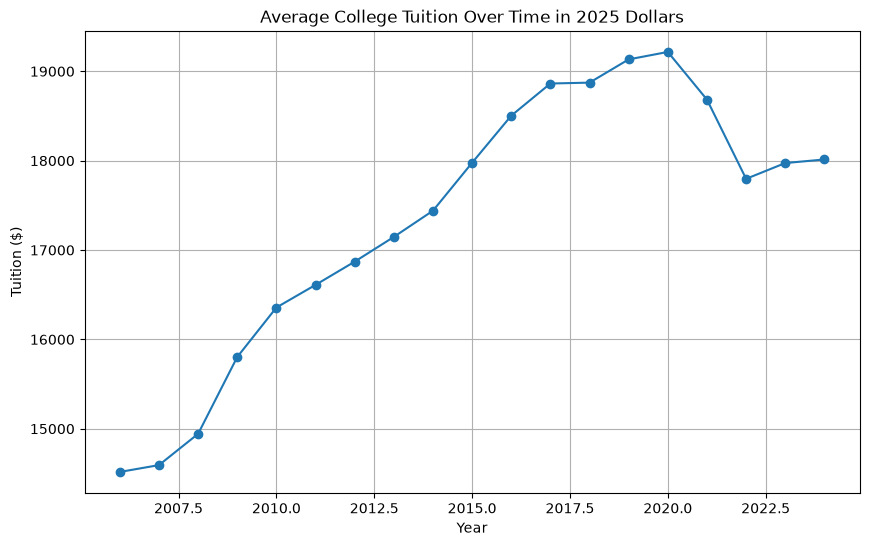

In [12]:
# Tuition Over Time Line Chart
# Shows the historical growth of tuition at public four-year institutions in the United States.
plt.figure(figsize=(10,6))
plt.plot(df["Year"], df["Average Tuition in 2025 Dollars"], marker="o")
plt.title("Average College Tuition Over Time in 2025 Dollars")
plt.xlabel("Year")
plt.ylabel("Tuition ($)")
plt.grid(True)
plt.show()

# Tuition is expected to increase steadily over time, indicating rising educational costs.

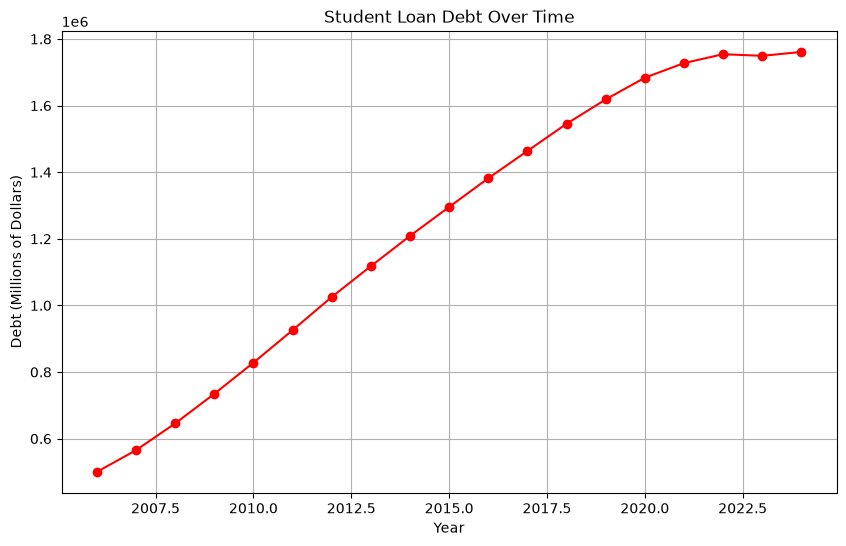

In [13]:
# Student Loan Debt Over Time Line Chart
# Shows the historical growth of student loan debt in the United States.

plt.figure(figsize=(10,6))
plt.plot(
    df["Year"],
    df["Student_Loan_Debt"],
    color="red",
    marker="o"
)

plt.title("Student Loan Debt Over Time")
plt.xlabel("Year")
plt.ylabel("Debt (Millions of Dollars)")
plt.grid(True)
plt.show()

# Allows comparison between debt accumulation and tuition growth over time, highlighting the financial burden on students.

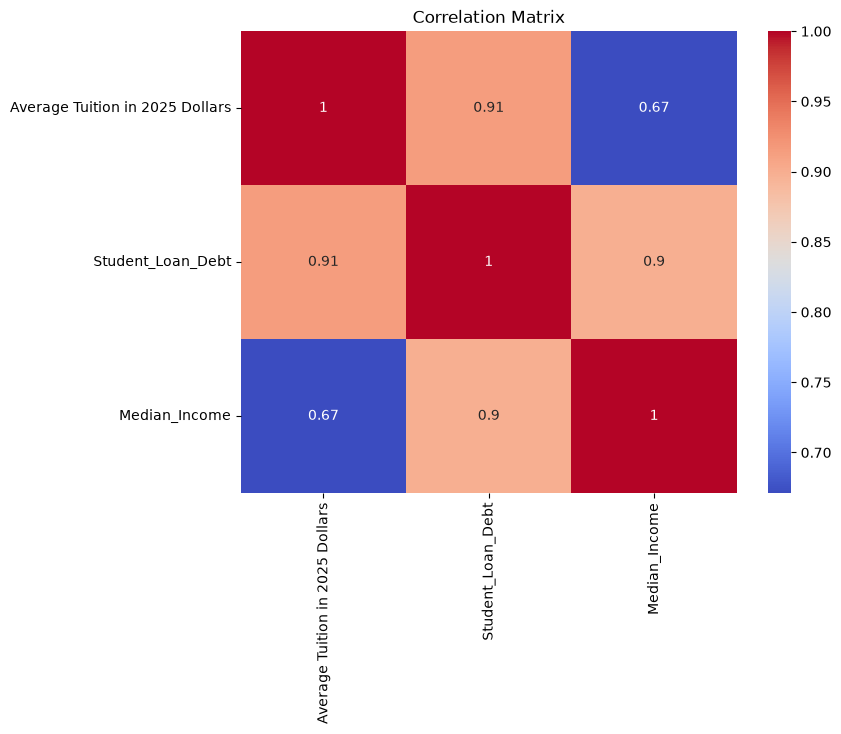

In [14]:
# Correlation Matrix Heatmap
# Shows the correlation between tuition, student loan debt, and median income in the United States.

plt.figure(figsize=(8,6))

sns.heatmap(
    df[[
        "Average Tuition in 2025 Dollars",
        "Student_Loan_Debt",
        "Median_Income"
    ]].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()

# Allows comparisons between deb accumulation and tuition growth.

# Potential findings:
#   -Strong positive correlation between Tuition and Student Loan Debt.
#   -Weaker relationship between Income and Debt.
#   -Positive relationship between Income and Tuition.

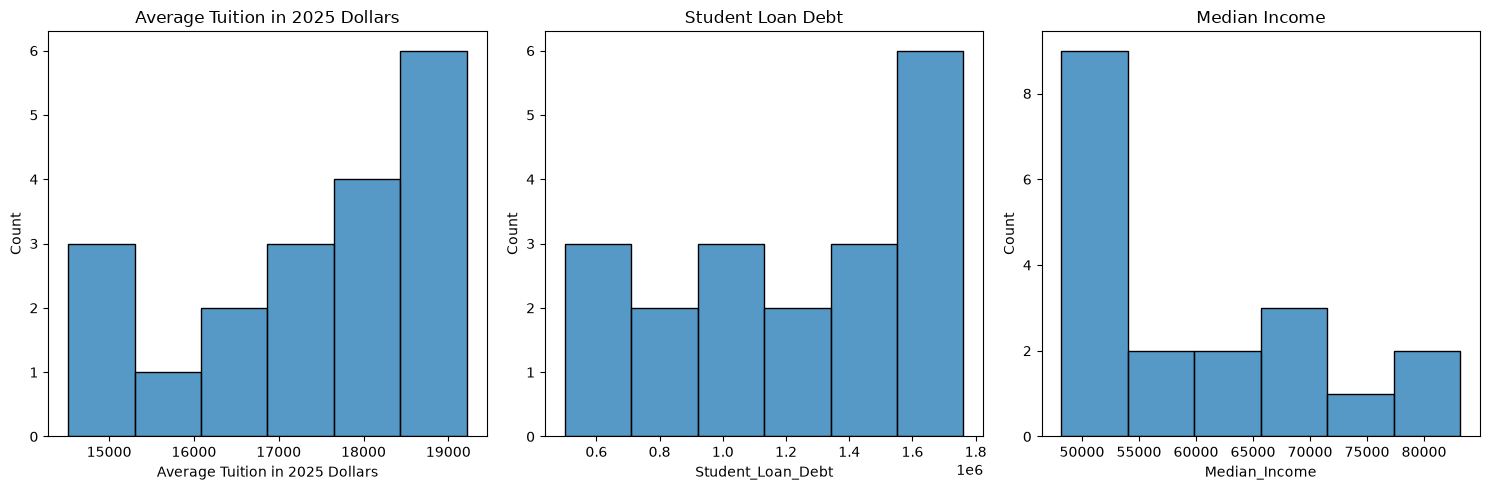

In [15]:
# Distribution Analysis
# Examines how each variable is distributed.
fig, axes = plt.subplots(1,3, figsize=(15,5))

sns.histplot(df["Average Tuition in 2025 Dollars"], ax=axes[0])
axes[0].set_title("Average Tuition in 2025 Dollars")

sns.histplot(df["Student_Loan_Debt"], ax=axes[1])
axes[1].set_title("Student Loan Debt")

sns.histplot(df["Median_Income"], ax=axes[2])
axes[2].set_title("Median Income")

plt.tight_layout()
plt.show()

# Helps identify skewness and unusual observations in the data, which may affect analysis and modeling.

What insights can be extracted?

. - Tuition has risen substantially over time.

. - Student loan debt appears to increase alongside tuition.

. - Household income has grown more slowly than tuition costs.

. - Affordability may have decreased over time.

In [16]:
# Are there correlations?
df.corr(numeric_only=True)

# 0.7 or greater = strong positive relationship
# 0.3-0.7 = moderate relationship
# below 0.3 = weak relationship

,Year,Public Two-Year at the Time,Public Four-Year at the Time,Private Nonprofit Four-Year at the Time,Public Two-Year in 2025 Dollars,Public Four-Year in 2025 Dollars,Private Nonprofit Four-Year in 2025 Dollars,Student_Loan_Debt,Median_Income,Average Tuition at the Time,Average Tuition in 2025 Dollars
Year,1.000000,0.988797,0.985159,0.997336,0.715261,0.704621,0.894842,0.988017,0.949879,0.998408,0.850340
Public Two-Year at the Time,0.988797,1.000000,0.996240,0.982212,0.800867,0.784584,0.928566,0.994107,0.900351,0.990838,0.900549
Public Four-Year at the Time,0.985159,0.996240,1.000000,0.978338,0.805573,0.806189,0.934310,0.992229,0.886838,0.988535,0.910102
Private Nonprofit Four-Year at the Time,0.997336,0.982212,0.978338,1.000000,0.688485,0.678538,0.884150,0.978170,0.960356,0.998349,0.834280
Public Two-Year in 2025 Dollars,0.715261,0.800867,0.805573,0.688485,1.000000,0.980098,0.920038,0.807745,0.485256,0.725060,0.959735
Public Four-Year in 2025 Dollars,0.704621,0.784584,0.806189,0.678538,0.980098,1.000000,0.913511,0.795089,0.463017,0.716724,0.958168
Private Nonprofit Four-Year in 2025 Dollars,0.894842,0.928566,0.934310,0.884150,0.920038,0.913511,1.000000,0.944334,0.748985,0.902050,0.991515
Student_Loan_Debt,0.988017,0.994107,0.992229,0.978170,0.807745,0.795089,0.944334,1.000000,0.898689,0.986630,0.914550
Median_Income,0.949879,0.900351,0.886838,0.960356,0.485256,0.463017,0.748985,0.898689,1.000000,0.944283,0.671002
Average Tuition at the Time,0.998408,0.990838,0.988535,0.998349,0.725060,0.716724,0.902050,0.986630,0.944283,1.000000,0.859097


In [17]:
# Missing Values
df.isnull().sum()

Year                                           0
Public Two-Year at the Time                    0
Public Four-Year at the Time                   0
Private Nonprofit Four-Year at the Time        0
Public Two-Year in 2025 Dollars                0
Public Four-Year in 2025 Dollars               0
Private Nonprofit Four-Year in 2025 Dollars    0
Student_Loan_Debt                              0
Median_Income                                  0
Average Tuition at the Time                    0
Average Tuition in 2025 Dollars                0
dtype: int64

In [18]:
# look for duplicate values
df.duplicated().sum()

# drop duplicates if they exist
# df = df.drop_duplicates()


np.int64(0)

In [19]:
# Verify data types
df.dtypes

Year                                             int64
Public Two-Year at the Time                    float64
Public Four-Year at the Time                   float64
Private Nonprofit Four-Year at the Time        float64
Public Two-Year in 2025 Dollars                float64
Public Four-Year in 2025 Dollars               float64
Private Nonprofit Four-Year in 2025 Dollars    float64
Student_Loan_Debt                              float64
Median_Income                                  float64
Average Tuition at the Time                    float64
Average Tuition in 2025 Dollars                float64
dtype: object

I already did a lot of cleaning before I merged the datasets, so my master dataset doesn't appear to need additional cleaning.

<Axes: >

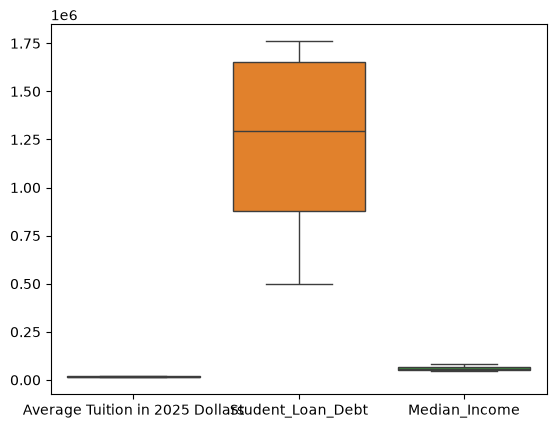

In [20]:
# look for outliers
# Because tuition and debt naturally rise over time, large values may represent genuine trends rather than errors.
sns.boxplot(data=df[[
    "Average Tuition in 2025 Dollars",
    "Student_Loan_Debt",
    "Median_Income"
]])

In [21]:
# Convert Data Types
df["Year"] = df["Year"].astype(int)

df["Average Tuition at the Time"] = pd.to_numeric(df["Average Tuition at the Time"])

df["Average Tuition in 2025 Dollars"] = pd.to_numeric(df["Average Tuition in 2025 Dollars"])

df["Student_Loan_Debt"] = pd.to_numeric(
    df["Student_Loan_Debt"]
)

df["Median_Income"] = pd.to_numeric(
    df["Median_Income"]
)

In [26]:
#train data and test data
# Split the data into training and testing sets

X = df[["Average Tuition in 2025 Dollars", "Median_Income", "Year"]]

y = df["Student_Loan_Debt"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Machine Learning Plan:

I plan to use a linear regression model to look at student loan debt. The predictors for this will be average tuition, median income, and the year. Linear regression is a continuous target variable that is easy to interpret, making it suitable for discovering relationships between education costs and debt.

My main challenge with this project is that I only have data from 1986-2025. Then, when I merged all of my datasets, it cut off anything before 2006. The problem with this is that smaller datsets limit model complexity. Another challenge is that the average tuition and year may be highly correlated, which would be multicollinearity because both variables are independent predictor variables. This can lead to inflated standard errors, unreliable p-values, unstable coefficients, or loss of interpretability. For example, if the average and tuition are correlated with each other, the model may struggle to determine if rising debt levels are caused by increasing tuition, the passage of time, or both. To address this issue, correlation analysis and Variance Inflation Factor (VIF) testing will be conducted. If severe multicollinearity is detected, highly correlated variables may be removed or Ridge Regression may be used to reduce its effects.

## Resources and References
*What resources and references have you used for this project?*
📝 <!-- Answer Below -->

In [22]:
# ⚠️ Make sure you run this cell at the end of your notebook before every submission!
!jupyter nbconvert --to python source.ipynb

[NbConvertApp] Converting notebook source.ipynb to python
[NbConvertApp] Writing 10659 bytes to source.py
